# 08 — RAG: retrieving passages from official documents

Decision D30. Corpus: 765 passages from Bank of Canada studies (R1–R4), Canada Gazette orders (R9–R11), Statistics Canada methodology (S3, S10) and the project's decision logs and summaries (EN, FR). Built by `src/rag/build_corpus.py`; retrieval in `app/rag.py`; evaluation by `src/rag/eval_rag.py` (this notebook reads its saved results, because the cross-encoder run takes several minutes and gigabytes of memory).

| Configuration | Idea, in one sentence |
|---|---|
| BM25 [N1] | Probabilistic keyword score: rare shared words count more, repeated words saturate, long passages are normalised. |
| Embeddings [N2, N3] | Multilingual sentence vectors: close meanings are close, across French and English. |
| RRF [N4] | Each ranker votes 1 / (60 + rank); votes are added. With and without the document title in front of each passage. |
| RRF + re-rank [N5, N6] | A multilingual cross-encoder reads question and passage together and re-orders the RRF top 20. |

Relevance judgements: 16 questions (10 English, 6 French) with gold documents and expected keywords (`data/reference/rag_eval.csv`). Metrics: recall@k, MRR, nDCG@5 [N7]; 95% bootstrap intervals [N8]; paired sign-flip randomization tests.

In [1]:
import sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(root / "src" / "rag"), str(root / "app")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import eval_rag as E
pd.set_option("display.width", 200)
res = pd.read_csv(root / "data/processed/rag_eval_retrieval.csv")
corpus = pd.read_csv(root / "app/data/rag_chunks.csv")
print(f"{len(corpus)} passages from {corpus.doc_id.nunique()} documents; {res.id.nunique()} questions; configurations: {list(res.config.unique())}")
corpus.groupby(["doc_id", "licence"]).size().rename("passages").reset_index()

765 passages from 13 documents; 16 questions; configurations: ['bm25', 'embeddings', 'rrf (no title)', 'rrf', 'rrf+rerank']


,doc_id,licence,passages
0,LOG-EN,Project document,56
1,LOG-FR,Project document,64
2,R1,Bank of Canada terms: reuse with attribution,11
3,R10,Open Government Licence - Canada,15
4,R11,Open Government Licence - Canada,9
5,R2,Bank of Canada terms: reuse with attribution,132
6,R3,Bank of Canada terms: reuse with attribution,27
7,R4,Bank of Canada terms: reuse with attribution,37
8,R9,Open Government Licence - Canada,6
9,S10,Open Government Licence - Canada,386


## 1. Overall results

In [2]:
E.summarise(res, ["config"]).round(3)

,recall@1,recall@3,recall@5,mrr,mrr_ci,ndcg@5,n
config,,,,,,,
bm25,0.562,0.688,0.688,0.641,[0.43; 0.85],0.470,16
embeddings,0.500,0.750,0.938,0.645,[0.46; 0.83],0.432,16
rrf (no title),0.500,0.625,0.625,0.565,[0.34; 0.78],0.333,16
rrf,0.562,0.562,0.812,0.631,[0.43; 0.84],0.463,16
rrf+rerank,0.750,0.812,0.938,0.806,[0.62; 0.95],0.679,16


## 2. By language of the question

In [3]:
E.summarise(res, ["config", "lang"])[["recall@1", "recall@5", "mrr", "ndcg@5", "n"]].round(3)

recall@1  recall@5    mrr  ndcg@5   n
config         lang                                       
bm25           en       0.600     0.700  0.675   0.527  10
               fr       0.500     0.667  0.583   0.374   6
embeddings     en       0.400     1.000  0.598   0.479  10
               fr       0.667     0.833  0.722   0.354   6
rrf (no title) en       0.600     0.700  0.660   0.396  10
               fr       0.333     0.500  0.406   0.230   6
rrf            en       0.700     1.000  0.770   0.607  10
               fr       0.333     0.500  0.399   0.223   6
rrf+rerank     en       0.700     1.000  0.790   0.738  10
               fr       0.833     0.833  0.833   0.581   6

## 3. Paired comparisons (same questions)

In [4]:
rr = res.pivot(index="id", columns="config", values="rr")
rows = []
for a, b in [("rrf", "bm25"), ("embeddings", "bm25"), ("rrf", "rrf (no title)"), ("rrf+rerank", "rrf"), ("rrf+rerank", "embeddings")]:
    rows.append({"comparison": f"{a} vs {b}", "mrr_diff": rr[a].mean() - rr[b].mean(), "p_value": E.paired_test(rr[a].to_numpy(), rr[b].to_numpy())})
pd.DataFrame(rows).round(3)

,comparison,mrr_diff,p_value
0,rrf vs bm25,-0.010,0.874
1,embeddings vs bm25,0.004,0.969
2,rrf vs rrf (no title),0.066,0.470
3,rrf+rerank vs rrf,0.175,0.121
4,rrf+rerank vs embeddings,0.161,0.094


## 4. Recall@k

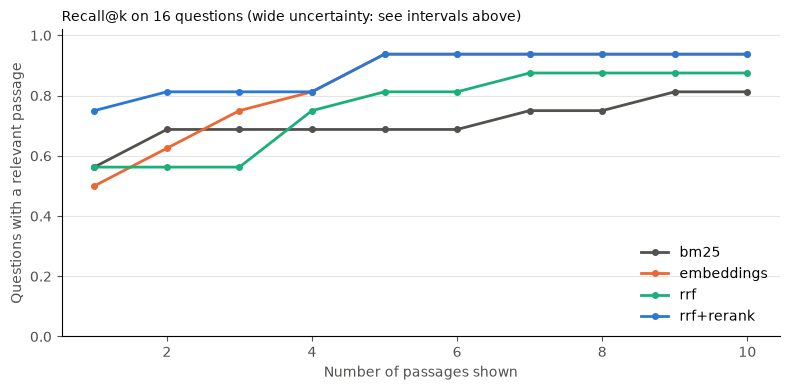

In [5]:
BLUE, ORANGE, AQUA, YELLOW, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e", "#e6e5e0"
fig, ax = plt.subplots(figsize=(8, 4))
for (cfg, col) in zip(["bm25", "embeddings", "rrf", "rrf+rerank"], [MUTED, ORANGE, AQUA, BLUE]):
    g = res[res.config == cfg]
    rec = [(g["rank"] <= k).mean() for k in range(1, 11)]
    ax.plot(range(1, 11), rec, color=col, lw=2, marker="o", ms=4, label=cfg)
ax.set_xlabel("Number of passages shown", color=MUTED); ax.set_ylabel("Questions with a relevant passage", color=MUTED)
ax.set_ylim(0, 1.02); ax.grid(axis="y", color=GRID); ax.tick_params(colors=MUTED)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Recall@k on 16 questions (wide uncertainty: see intervals above)", color=INK, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## 5. Questions missed at rank 1 by the light configurations

In [6]:
q = pd.read_csv(root / "data/reference/rag_eval.csv")[["id", "lang", "question", "gold_docs"]]
p = res.pivot(index="id", columns="config", values="rank")
q.merge(p, left_on="id", right_index=True).query("embeddings != 1 or rrf != 1")

,id,lang,question,gold_docs,bm25,embeddings,rrf,rrf (no title),rrf+rerank
0,Q01,en,What pass-through did the Bank of Canada find ...,R1|R2,2.0,4.0,4.0,1.0,2.0
1,Q02,en,Which data did the Bank of Canada use to measu...,R1|R2,9.0,3.0,4.0,NaN,5.0
2,Q03,en,What did the 2018 tariff episode teach about p...,R3,7.0,2.0,1.0,1.0,1.0
4,Q05,en,What was the surtax rate of the 2018 order on ...,R10,NaN,5.0,5.0,10.0,5.0
5,Q06,en,Which goods were removed from the 2018 surtax ...,R11,1.0,5.0,1.0,1.0,1.0
6,Q07,en,Why do monthly average retail prices not measu...,S3,1.0,2.0,1.0,NaN,1.0
12,Q13,fr,Quand la surtaxe américaine de 2018 sur les au...,R9|LOG-FR|LOG-EN,NaN,3.0,NaN,NaN,NaN
13,Q14,fr,Comment Statistique Canada tient-elle compte d...,S10,NaN,1.0,7.0,10.0,1.0
14,Q15,fr,Pourquoi les prix moyens de détail ne mesurent...,S3|LOG-FR|LOG-EN,1.0,NaN,NaN,NaN,1.0
15,Q16,fr,Comment les tarifs sur les intrants se transme...,R4|LOG-FR|LOG-EN,2.0,1.0,4.0,3.0,1.0


## 6. Findings

Written up in D30 (decision log).